# SRTMGL1 V003 — Sidi Salem–Qallin static elevation EDA

This notebook analyzes only the pilot bbox [30.70, 31.05, 30.91, 31.30] (W, S, E, N). It is a static terrain dataset, not a rainfall time series.


## 1. Dataset description
Plan: inspect the supplied NASA SRTMGL1 V003 HGT tile, confirm its spatial metadata, and analyze pilot pixel centers only. SRTM is primarily from February 2000, sampled at one arc-second (~30 m), with WGS84 horizontal coordinates and EGM96 meter elevations.


### Environment setup — run once before the imports

This notebook requires `rasterio` and `pyproj` in the active Jupyter kernel environment. Run the next cell once, let any error appear in full, then use **Kernel → Restart Kernel** and run the notebook from the top. `%pip` deliberately targets the active notebook environment rather than an unrelated terminal Python installation.


In [1]:
# Run once in this notebook kernel; do not suppress installation errors.
%pip install rasterio pyproj


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Run after restarting the kernel to confirm the active kernel can import both dependencies.
import rasterio
import pyproj
print(f'rasterio: {rasterio.__version__}')
print(f'pyproj: {pyproj.__version__}')


rasterio: 1.5.2
pyproj: 3.8.0


In [3]:
# Reproducible SRTM inspection. Run from notebooks/ or the SRTM_Dataset root.
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import from_bounds, Window, transform as window_transform
from pyproj import Transformer

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
RAW = ROOT / 'data' / 'raw' / 'N31E030.hgt'
GRID = ROOT / 'data' / 'processed' / 'grid_1km.csv'
OUT = ROOT / 'data' / 'processed' / 'srtm_static.csv'
assert RAW.is_file(), f'Missing raw raster: {RAW}'
PILOT_BBOX = (30.70, 31.05, 30.91, 31.30)  # W, S, E, N, WGS84
PILOT_CENTER = (31.175, 30.805)             # lat, lon
UTM_CRS = 'EPSG:32636'
FILL_VALUE = -32768

# Status flags are reset at the beginning of every fresh run.
RUN_STATUS = {
    'raster_inspected': False,
    'raster_eda_completed': False,
    'grid_available': False,
    'grid_validated': False,
    'aggregation_completed': False,
    'exported_this_run': False,
}
plt.style.use('seaborn-v0_8-whitegrid')


## 2. Download provenance
Plan: report only supplied filename/size and avoid inventing the access date.


In [4]:
# Download/access date is not inferred from a filesystem timestamp.
file_size = RAW.stat().st_size
print(f'Actual filename: {RAW.name}')
print(f'File size: {file_size:,} bytes ({file_size / 1024**2:.2f} MiB)')
print('Download/access date: unknown (not recorded in the supplied files)')
print('Source: NASA SRTMGL1 Version 003 / NASA Earthdata')
print('Links: https://www.earthdata.nasa.gov/data/catalog/lpcloud-srtmgl1-003')
print('       https://doi.org/10.5067/MEaSUREs/SRTM/SRTMGL1.003')


Actual filename: N31E030.hgt
File size: 25,934,402 bytes (24.73 MiB)
Download/access date: unknown (not recorded in the supplied files)
Source: NASA SRTMGL1 Version 003 / NASA Earthdata
Links: https://www.earthdata.nasa.gov/data/catalog/lpcloud-srtmgl1-003
       https://doi.org/10.5067/MEaSUREs/SRTM/SRTMGL1.003


## 3. Initial inspection
Plan: inspect driver, CRS, bounds, transform, dimensions, dtype, nodata, coverage, and outward-rounded source window without resampling.


In [5]:
with rasterio.open(RAW) as src:
    print('Driver:', src.driver)
    print('CRS:', src.crs)
    print('Bounds:', src.bounds)
    print('Dimensions (width, height):', src.width, src.height)
    print('Transform:', src.transform)
    print('Dtype:', src.dtypes[0])
    print('Nodata declared:', src.nodata)
    print('Native resolution (degrees):', src.res)
    west, south, east, north = PILOT_BBOX
    full_coverage = src.bounds.left <= west and src.bounds.bottom <= south and src.bounds.right >= east and src.bounds.top >= north
    print('Tile covers full pilot bbox:', full_coverage)
    assert full_coverage, 'Pilot bbox is not fully covered by this raster.'
    assert src.crs and src.crs.to_epsg() == 4326, 'Expected WGS84 geographic horizontal CRS.'
    assert src.dtypes[0] in ('int16', 'int32'), 'Unexpected elevation dtype.'
    # Expand fractional window outward; reading source pixels only, never resampling.
    float_window = from_bounds(west, south, east, north, transform=src.transform)
    col0 = int(np.floor(float_window.col_off)); row0 = int(np.floor(float_window.row_off))
    col1 = int(np.ceil(float_window.col_off + float_window.width)); row1 = int(np.ceil(float_window.row_off + float_window.height))
    window = Window(col0, row0, col1-col0, row1-row0)
    cropped_transform = window_transform(window, src.transform)
    data = src.read(1, window=window, masked=True)
print('Fractional window:', float_window)
print('Outward-rounded source window:', window)
print('Correct window transform:', cropped_transform)
RUN_STATUS['raster_inspected'] = True


Driver: SRTMHGT
CRS: EPSG:4326
Bounds: BoundingBox(left=29.999861111111112, bottom=30.999861111111112, right=31.00013888888889, top=32.00013888888889)
Dimensions (width, height): 3601 3601
Transform: | 0.00, 0.00, 30.00|
| 0.00,-0.00, 32.00|
| 0.00, 0.00, 1.00|
Dtype: int16
Nodata declared: -32768.0
Native resolution (degrees): (0.0002777777777777778, 0.0002777777777777778)
Tile covers full pilot bbox: True
Fractional window: Window(col_off=np.float64(2520.4999999999927), row_off=np.float64(2520.5000000000055), width=np.float64(756.0000000000032), height=np.float64(900.0))
Outward-rounded source window: Window(col_off=2520, row_off=2520, width=757, height=901)
Correct window transform: | 0.00, 0.00, 30.70|
| 0.00,-0.00, 31.30|
| 0.00, 0.00, 1.00|


## 4. Missing values
Plan: respect raster masks and the -32768 fill value; retain zero/negative elevation as valid unless masked.


Raster shape: (901, 757)
Coordinate shapes: (901, 757) (901, 757)
Mask shapes: (901, 757) (901, 757) (901, 757)
{'pilot_source_pixel_centers': 681300, 'pilot_valid_pixels': 681300, 'pilot_masked_or_fill_pixels': 0, 'pilot_masked_or_fill_pct': 0.0}
count    681300.000000
mean          3.528159
std           1.861466
min          -6.000000
5%            1.000000
25%           2.000000
50%           3.000000
75%           5.000000
95%           7.000000
max          18.000000
dtype: float64


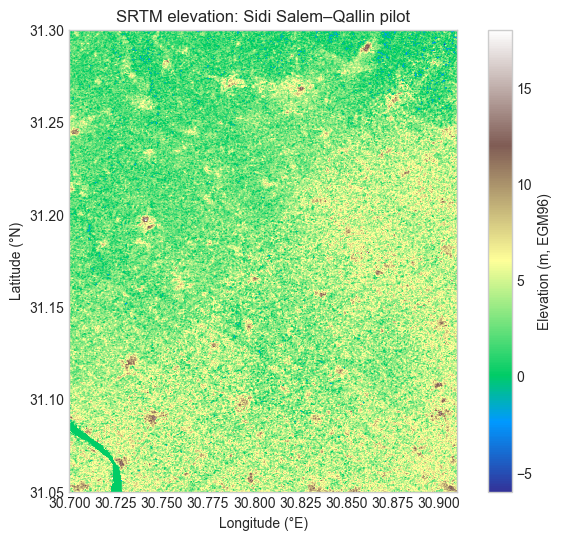

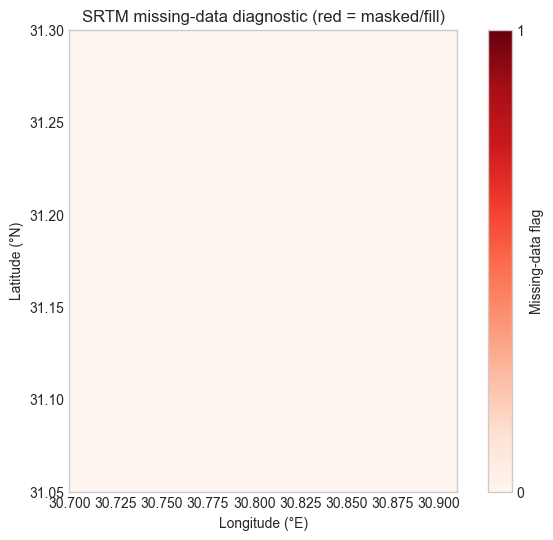

No masked or -32768 fill pixels occur within the exact pilot bbox.


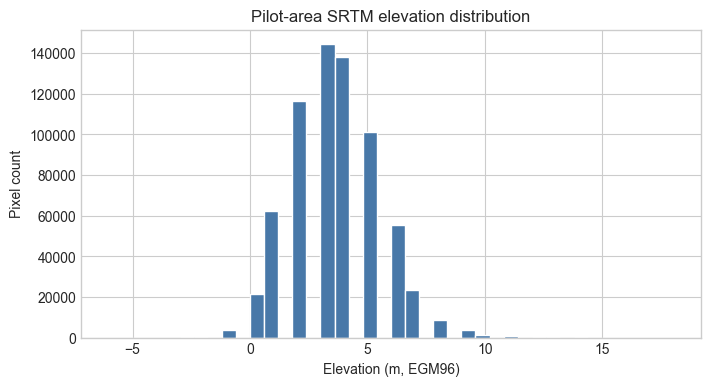

In [6]:
# Pixel-center coordinates and masks must retain data.shape. The SRTM inspection cell
# verifies the source is EPSG:4326 before this geographic bbox test.
assert data.ndim == 2, 'Expected a 2-D elevation raster.'
rows, cols = np.indices(data.shape)

xs, ys = rasterio.transform.xy(
    cropped_transform,
    rows.ravel(),
    cols.ravel(),
    offset="center",
)

lon = np.asarray(xs, dtype="float64").reshape(data.shape)
lat = np.asarray(ys, dtype="float64").reshape(data.shape)

inside = (
    (lon >= west) & (lon <= east)
    & (lat >= south) & (lat <= north)
)

source_mask = (
    np.ma.getmaskarray(data)
    | (np.asarray(data) == FILL_VALUE)
)

assert lon.shape == lat.shape == data.shape
assert inside.shape == source_mask.shape == data.shape

pilot_mask = source_mask | ~inside
pilot = np.ma.array(
    np.asarray(data, dtype="float64"),
    mask=pilot_mask,
)

candidate_pixels = int(inside.sum())
valid_pixels = int((inside & ~source_mask).sum())

print("Raster shape:", data.shape)
print("Coordinate shapes:", lon.shape, lat.shape)
print("Mask shapes:", source_mask.shape, inside.shape, pilot_mask.shape)

nodata_pixels = int((inside & source_mask).sum())
print({'pilot_source_pixel_centers': candidate_pixels, 'pilot_valid_pixels': valid_pixels,
       'pilot_masked_or_fill_pixels': nodata_pixels,
       'pilot_masked_or_fill_pct': 100*nodata_pixels/candidate_pixels if candidate_pixels else np.nan})
print(pd.Series(pilot.compressed()).describe(percentiles=[.05,.25,.5,.75,.95]))
if valid_pixels == 0:
    raise RuntimeError('No valid pilot pixels; no aggregation can be performed.')

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.pcolormesh(lon, lat, np.where(pilot.mask, np.nan, pilot.data), shading='auto', cmap='terrain')
ax.set(title='SRTM elevation: Sidi Salem–Qallin pilot', xlabel='Longitude (°E)', ylabel='Latitude (°N)')
ax.set_aspect('equal'); fig.colorbar(im, ax=ax, label='Elevation (m, EGM96)')
plt.show()
# Spatial missing-data diagnostic. White means outside the exact pilot bbox; red means masked/fill.
fig, ax = plt.subplots(figsize=(8, 6))
missing_display = np.where(inside, source_mask.astype(float), np.nan)
im = ax.pcolormesh(lon, lat, missing_display, shading='auto', cmap='Reds', vmin=0, vmax=1)
ax.set(title='SRTM missing-data diagnostic (red = masked/fill)', xlabel='Longitude (°E)', ylabel='Latitude (°N)')
ax.set_aspect('equal'); fig.colorbar(im, ax=ax, ticks=[0, 1], label='Missing-data flag')
plt.show()
if nodata_pixels == 0:
    print('No masked or -32768 fill pixels occur within the exact pilot bbox.')

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(pilot.compressed(), bins=40, color='#4878a8', edgecolor='white')
ax.set(title='Pilot-area SRTM elevation distribution', xlabel='Elevation (m, EGM96)', ylabel='Pixel count')
plt.show()
RUN_STATUS['raster_eda_completed'] = True
# Zero and negative elevations are valid terrain values and remain in the analysis.


## 5. Simple plots
Plan: show a north-up geographic elevation map and histogram; show the grid-cell map only if the shared grid exists.


## 6. Problems and quality checks
Plan: validate the provided grid unchanged before aggregation. No interpolation, fabricated pixels, or silent value removal occurs.


Grid validation PASS: 560 unchanged, uniquely keyed 1-km cells with IDs 1–560.
{'total_pilot_source_pixels': 681300, 'total_pilot_valid_pixels': 681300, 'assigned_source_pixels': 673251, 'unassigned_source_pixels': 8049, 'assigned_valid_pixels': 673251, 'unassigned_valid_pixels': 8049}
Unmatched grid keys: 35; expected boundary exclusions: 35; unexpected interior gaps: 0


,x_min_m,y_max_m,center_lon,center_lat,center_inside_pilot
0,281000.0,3466000.0,30.704212,31.303380,False
35,282000.0,3466000.0,30.714712,31.303567,False
73,283000.0,3466000.0,30.725212,31.303753,False
111,284000.0,3466000.0,30.735712,31.303939,False
148,285000.0,3466000.0,30.746212,31.304124,False
186,286000.0,3466000.0,30.756713,31.304308,False
753,301000.0,3465000.0,30.914427,31.297947,False
18165,301000.0,3464000.0,30.914626,31.288930,False
43147,301000.0,3463000.0,30.914824,31.279913,False
67371,301000.0,3462000.0,30.915023,31.270897,False


,cell_id,source_pixel_count,valid_pixel_count,elev_mean_m,elev_min_m,elev_max_m
0,1.0,1146,1146,2.190227,0.0,6.0
1,2.0,1218,1218,1.982759,-1.0,6.0
2,3.0,1241,1241,1.774376,-1.0,6.0
3,4.0,1227,1227,1.458028,-1.0,5.0
4,5.0,1218,1218,1.800493,-2.0,7.0
...,...,...,...,...,...,...
555,556.0,1138,1138,5.130931,1.0,11.0
556,557.0,1146,1146,4.619546,0.0,9.0
557,558.0,1165,1165,5.195708,1.0,10.0
558,559.0,1198,1198,5.696995,2.0,11.0


Cells without valid elevation: []
EXPORTED: C:\Users\o3995\Downloads\NASA_Space_Apps_Cairo\Work\SRTM_Dataset\data\processed\srtm_static.csv (560 rows, index=False)


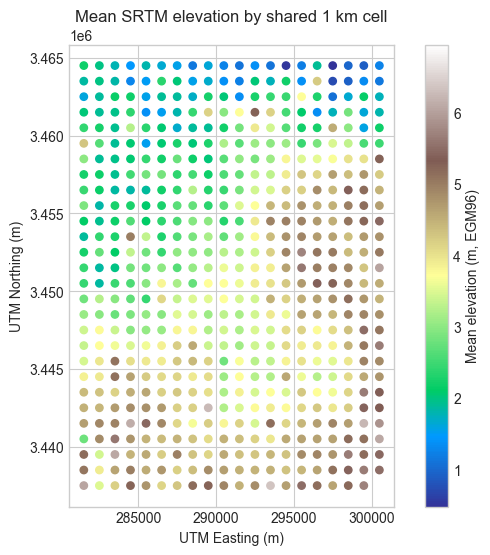

In [7]:
# Grid validation, pixel assignment, and export. This cell makes no change to the team grid.
required_grid_cols = ['cell_id', 'row', 'col', 'x_min_m', 'x_max_m', 'y_min_m', 'y_max_m', 'x_m', 'y_m', 'lat', 'lon']
RUN_STATUS['grid_available'] = GRID.is_file()
if not GRID.is_file():
    print(f'BLOCKED: shared team grid is absent: {GRID}')
    print('Raster EDA is complete, but aggregation and srtm_static.csv export require the unchanged 560-cell grid.')
else:
    grid = pd.read_csv(GRID)
    missing_cols = [c for c in required_grid_cols if c not in grid.columns]
    assert not missing_cols, f'Grid lacks required columns: {missing_cols}'
    assert len(grid) == 560, f'Expected 560 grid rows, found {len(grid)}'
    cell_numeric = pd.to_numeric(grid['cell_id'], errors='coerce')
    assert cell_numeric.notna().all() and np.all(np.equal(cell_numeric, np.floor(cell_numeric))), 'cell_id must be nonmissing integers'
    grid['cell_id'] = cell_numeric.astype('int64')
    assert grid.cell_id.is_unique and set(grid.cell_id) == set(range(1, 561)), 'cell_id must be unique and exactly 1–560'
    numeric_cols = ['row', 'col', 'x_min_m', 'x_max_m', 'y_min_m', 'y_max_m', 'x_m', 'y_m', 'lat', 'lon']
    grid[numeric_cols] = grid[numeric_cols].apply(pd.to_numeric, errors='coerce')
    assert np.isfinite(grid[numeric_cols].to_numpy()).all(), 'Grid coordinate/bound fields must be finite numeric values'
    assert not grid.duplicated(['x_min_m', 'y_max_m']).any(), 'Duplicate (x_min_m, y_max_m) spatial keys'
    assert not grid.duplicated(['row', 'col']).any(), 'Duplicate (row, col) keys'
    assert np.allclose(grid.x_max_m-grid.x_min_m, 1000, rtol=0, atol=1e-6) and np.allclose(grid.y_max_m-grid.y_min_m, 1000, rtol=0, atol=1e-6), 'Grid bounds are not 1-km squares'
    assert np.allclose(grid.x_min_m, np.round(grid.x_min_m / 1000) * 1000, rtol=0, atol=1e-6) and np.allclose(grid.y_max_m, np.round(grid.y_max_m / 1000) * 1000, rtol=0, atol=1e-6), 'Grid bounds are not on the aligned 1-km UTM lattice'
    assert np.allclose(grid.x_m, (grid.x_min_m+grid.x_max_m)/2, rtol=0, atol=1e-6) and np.allclose(grid.y_m, (grid.y_min_m+grid.y_max_m)/2, rtol=0, atol=1e-6), 'x_m/y_m disagree with bound centers'
    to_wgs84 = Transformer.from_crs(UTM_CRS, 'EPSG:4326', always_xy=True)
    expected_lon, expected_lat = to_wgs84.transform(grid.x_m.to_numpy(), grid.y_m.to_numpy())
    assert np.all(np.abs(grid.lon.to_numpy()-expected_lon) <= 0.500001e-6) and np.all(np.abs(grid.lat.to_numpy()-expected_lat) <= 0.500001e-6), 'Grid lat/lon disagree with UTM centers beyond six-decimal rounding'
    RUN_STATUS['grid_validated'] = True
    print('Grid validation PASS: 560 unchanged, uniquely keyed 1-km cells with IDs 1–560.')

    # Flatten only the same 2-D inside mask for every source-pixel field, preserving alignment.
    all_inside = inside
    valid_inside = inside & ~source_mask
    to_utm = Transformer.from_crs('EPSG:4326', UTM_CRS, always_xy=True)
    source_lon, source_lat = lon[all_inside], lat[all_inside]
    source_x, source_y = to_utm.transform(source_lon, source_lat)
    source = pd.DataFrame({
        'lon': source_lon, 'lat': source_lat, 'x_m': source_x, 'y_m': source_y,
        'elevation_m': np.asarray(data, dtype='float64')[all_inside],
        'is_valid': ~source_mask[all_inside],
    })
    source['x_min_m'] = np.floor(source.x_m / 1000) * 1000
    source['y_max_m'] = np.floor(source.y_m / 1000) * 1000 + 1000
    source = source.merge(grid[['cell_id', 'x_min_m', 'y_max_m']], on=['x_min_m', 'y_max_m'], how='left', validate='many_to_one')
    assigned = source.cell_id.notna()
    assigned_valid = assigned & source.is_valid
    print({'total_pilot_source_pixels': len(source), 'total_pilot_valid_pixels': int(source.is_valid.sum()),
           'assigned_source_pixels': int(assigned.sum()), 'unassigned_source_pixels': int((~assigned).sum()),
           'assigned_valid_pixels': int(assigned_valid.sum()), 'unassigned_valid_pixels': int((source.is_valid & ~assigned).sum())})
    assert len(source) == candidate_pixels and int(source.is_valid.sum()) == valid_pixels, 'Pixel accounting differs from pilot mask diagnostics'

    # Unmatched keys whose 1-km centers lie outside the pilot are expected edge exclusions.
    unmatched_keys = source.loc[~assigned, ['x_min_m', 'y_max_m']].drop_duplicates()
    if len(unmatched_keys):
        edge_lon, edge_lat = to_wgs84.transform(unmatched_keys.x_min_m.to_numpy()+500, unmatched_keys.y_max_m.to_numpy()-500)
        unmatched_keys = unmatched_keys.assign(center_lon=edge_lon, center_lat=edge_lat)
        unmatched_keys['center_inside_pilot'] = ((unmatched_keys.center_lon >= west) & (unmatched_keys.center_lon <= east) & (unmatched_keys.center_lat >= south) & (unmatched_keys.center_lat <= north))
        expected_boundary = unmatched_keys.loc[~unmatched_keys.center_inside_pilot]
        interior_gaps = unmatched_keys.loc[unmatched_keys.center_inside_pilot]
        print(f'Unmatched grid keys: {len(unmatched_keys)}; expected boundary exclusions: {len(expected_boundary)}; unexpected interior gaps: {len(interior_gaps)}')
        display(unmatched_keys)
        assert interior_gaps.empty, 'Unexpected interior grid-key gaps block export.'
    else:
        print('All pilot pixel keys matched the shared grid.')

    source_counts = source.groupby('cell_id', dropna=True).size().rename('source_pixel_count')
    valid_records = source.loc[assigned_valid, ['cell_id', 'elevation_m']]
    valid_counts = valid_records.groupby('cell_id').size().rename('valid_pixel_count')
    elevation_stats = valid_records.groupby('cell_id').elevation_m.agg(elev_mean_m='mean', elev_min_m='min', elev_max_m='max')
    diagnostics = (grid[['cell_id']].set_index('cell_id').join(source_counts).join(valid_counts).join(elevation_stats).fillna({'source_pixel_count': 0, 'valid_pixel_count': 0}))
    diagnostics[['source_pixel_count', 'valid_pixel_count']] = diagnostics[['source_pixel_count', 'valid_pixel_count']].astype('int64')
    display(diagnostics.reset_index())
    assert diagnostics.source_pixel_count.sum() == int(assigned.sum()) and diagnostics.valid_pixel_count.sum() == int(assigned_valid.sum()), 'Per-cell counts do not reconcile'

    final = diagnostics.reset_index()[['cell_id', 'elev_mean_m', 'elev_min_m', 'elev_max_m']].sort_values('cell_id').reset_index(drop=True)
    assert len(final) == 560 and final.cell_id.is_unique and final.cell_id.tolist() == list(range(1, 561))
    stats_values = final[['elev_mean_m', 'elev_min_m', 'elev_max_m']].to_numpy(dtype=float)
    assert np.isfinite(stats_values[~np.isnan(stats_values)]).all(), 'Non-finite output statistics'
    assert not final.isin([FILL_VALUE]).any().any(), 'Fill code reached output'
    populated = final.elev_mean_m.notna()
    assert (final.loc[populated, 'elev_min_m'] <= final.loc[populated, 'elev_mean_m']).all()
    assert (final.loc[populated, 'elev_mean_m'] <= final.loc[populated, 'elev_max_m']).all()
    assert final.loc[~populated, ['elev_min_m', 'elev_max_m']].isna().all().all(), 'Missing elevation statistics must be consistently empty'
    print('Cells without valid elevation:', final.loc[~populated, 'cell_id'].tolist())
    RUN_STATUS['aggregation_completed'] = True
    final.to_csv(OUT, index=False)
    RUN_STATUS['exported_this_run'] = True
    print(f'EXPORTED: {OUT} ({len(final)} rows, index=False)')

    fig, ax = plt.subplots(figsize=(8, 6))
    plot_grid = grid.merge(final[['cell_id', 'elev_mean_m']], on='cell_id', how='left')
    sc = ax.scatter(plot_grid.x_m, plot_grid.y_m, c=plot_grid.elev_mean_m, s=28, cmap='terrain')
    ax.set(title='Mean SRTM elevation by shared 1 km cell', xlabel='UTM Easting (m)', ylabel='UTM Northing (m)', aspect='equal')
    fig.colorbar(sc, ax=ax, label='Mean elevation (m, EGM96)')
    plt.show()


## 7. Conclusion
Plan: document actual QC output and use elevation only as cautious relative-terrain context.


In [8]:
# This conclusion uses only status flags set in the current kernel run, never old files or saved outputs.
print('SRTM current-run conclusion')
print('Status flags:', RUN_STATUS)
if RUN_STATUS['raster_eda_completed']:
    values = pilot.compressed()
    print({'pilot_source_pixels': candidate_pixels, 'pilot_valid_pixels': valid_pixels,
           'pilot_missing_pixels': nodata_pixels,
           'pilot_missing_percent': 100 * nodata_pixels / candidate_pixels if candidate_pixels else np.nan,
           'elevation_min_m': float(values.min()), 'elevation_mean_m': float(values.mean()),
           'elevation_max_m': float(values.max())})
    print('Raster EDA completed in this run.')
else:
    print('Raster EDA was not completed in this current run.')

if not RUN_STATUS['grid_available']:
    print('Grid aggregation/export BLOCKED: provide Mostafa Sherief\'s unchanged shared grid_1km.csv at data/processed/grid_1km.csv.')
elif not RUN_STATUS['grid_validated']:
    print('Grid was available but did not complete validation; no export is authorized.')
elif not RUN_STATUS['aggregation_completed']:
    print('Grid validated but aggregation did not complete; no export is authorized.')
else:
    print({'assigned_source_pixels': int(assigned.sum()), 'unassigned_source_pixels': int((~assigned).sum()),
           'assigned_valid_pixels': int(assigned_valid.sum()), 'unassigned_valid_pixels': int((source.is_valid & ~assigned).sum()),
           'cells_without_valid_elevation': final.loc[final.elev_mean_m.isna(), 'cell_id'].tolist()})
    print('Grid validation and aggregation completed in this run.')
    print('Final CSV exported during this run:', RUN_STATUS['exported_this_run'])

print('SRTM is static terrain context, primarily acquired in February 2000, not a 2016–2024 time series.')
print('Use this very flat pilot’s elevations only as cautious relative-terrain context. Radar elevation can include vegetation/buildings, and vertical error can exceed local relief.')
print('Do not infer drainage, flooding, salinity, or crop suitability from these values alone.')
print('This notebook intentionally does not calculate slope, flow accumulation, flood/erosion risk, salinity, or crop recommendations.')


SRTM current-run conclusion
Status flags: {'raster_inspected': True, 'raster_eda_completed': True, 'grid_available': True, 'grid_validated': True, 'aggregation_completed': True, 'exported_this_run': True}
{'pilot_source_pixels': 681300, 'pilot_valid_pixels': 681300, 'pilot_missing_pixels': 0, 'pilot_missing_percent': 0.0, 'elevation_min_m': -6.0, 'elevation_mean_m': 3.5281594011448703, 'elevation_max_m': 18.0}
Raster EDA completed in this run.
{'assigned_source_pixels': 673251, 'unassigned_source_pixels': 8049, 'assigned_valid_pixels': 673251, 'unassigned_valid_pixels': 8049, 'cells_without_valid_elevation': []}
Grid validation and aggregation completed in this run.
Final CSV exported during this run: True
SRTM is static terrain context, primarily acquired in February 2000, not a 2016–2024 time series.
Use this very flat pilot’s elevations only as cautious relative-terrain context. Radar elevation can include vegetation/buildings, and vertical error can exceed local relief.
Do not infe